# 04 · Modeling: Will a Steam game reach 50K+ owners?

**DATA 230 · Group 6** · Steam Game Analysis
**Main question:** *What makes a Steam game commercially successful?*

This notebook continues the preliminary ML plan from the mid-presentation:

| EDA finding | Modeling decision taken here |
|---|---|
| Only 14.6% of games reach 50K+ owners | Class weights; judge models by **PR-AUC, F1, recall**, not accuracy |
| Price effect is non-linear and interacts with genre | Compare a **logistic-regression baseline** with **Random Forest** and **XGBoost** |
| Hit rate falls from ~71% (pre-2010) to ~4% (2025) | **Time-based split**: train on releases ≤ 2021, test on 2022+ |
| Experienced publishers have higher hit rates | Rebuild publisher experience as **prior releases only** (no future games) |
| Which features matter? | **Permutation importance** + **SHAP**, checked against the EDA charts |

**Target:** `success_50k = 1` when the SteamSpy owner-range lower bound is ≥ 50,000.
**Input:** `steam_clean.csv` (95,787 games × 67 columns) from `01–03` cleaning notebooks. The file is 63 MB, so it lives in the team Google Drive, not GitHub - download it to `data/clean_output/`.

**Outputs:** figures → `figures/ml/`, metrics / predictions / model → `results/ml/` (used by the Streamlit and Dash dashboards).

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (average_precision_score, roc_auc_score, f1_score, precision_score,
                             recall_score, precision_recall_curve, roc_curve, confusion_matrix)
import xgboost as xgb
import shap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Paths (run from the notebooks/ folder)
ROOT = Path("..").resolve()   # = Group6_ML_upload, so figures/results land in the right folders
candidates = [ROOT / "data" / "clean_output" / "steam_clean.csv",   # repo layout
              ROOT / "steam_clean.csv",
              ROOT.parent / "steam_clean.csv"]                       # your "final project" folder
DATA_PATH = next((p for p in candidates if p.exists()), None)
assert DATA_PATH is not None, "steam_clean.csv not found - put it in data/clean_output/"
print("Using", DATA_PATH)
FIG_DIR = ROOT / "figures" / "ml"
OUT_DIR = ROOT / "results" / "ml"
FIG_DIR.mkdir(parents=True, exist_ok=True); OUT_DIR.mkdir(parents=True, exist_ok=True)
print("Figures will be saved to:", FIG_DIR)
print("Results will be saved to:", OUT_DIR)
print("xgboost", xgb.__version__, "| shap", shap.__version__)

/Users/chinmayibolisetty/Library/spyder-6/envs/myenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Using /Users/chinmayibolisetty/Desktop/data230/final project/steam_clean.csv
Figures will be saved to: /Users/chinmayibolisetty/Desktop/data230/final project/Group6_ML_final/figures/ml
Results will be saved to: /Users/chinmayibolisetty/Desktop/data230/final project/Group6_ML_final/results/ml
xgboost 3.4.1 | shap 0.54.1


In [2]:
# Shared chart style - viridis colour-blind-safe palette, used in every ML figure
from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D

INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
# Colours sampled from viridis: perceptually uniform and readable with protanopia, deuteranopia and tritanopia
C = {"Logistic Regression": "#414487", "Random Forest": "#1e9c89", "XGBoost": "#5ec962"}  # purple-blue / teal / green
HATCH = {"Logistic Regression": "///", "Random Forest": "...", "XGBoost": ""}   # second cue so colour is never the only one
MARK = {"Logistic Regression": "o", "Random Forest": "s", "XGBoost": "^"}
BASE = "#8a8984"
SHAP_CMAP = "viridis"   # low (purple) -> high (yellow)
HEAT_CMAP = "viridis"   # perceptually uniform and colour-blind safe

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight", "savefig.pad_inches": 0.15,
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "font.size": 11, "axes.titlesize": 13.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.edgecolor": "#bdbcb7", "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "legend.fontsize": 10, "lines.linewidth": 2,
    "hatch.color": "white", "hatch.linewidth": 1.3,
})

def label_axes(ax, title, xlabel, ylabel=None):
    # Bold title top-left; y-axis label written horizontally above the axis (no rotated text)
    ax.set_title(title, loc="left", pad=28 if ylabel else 12)
    ax.set_xlabel(xlabel, labelpad=8)
    ax.set_ylabel("")
    ax._ylab = None
    if ylabel:
        ax._ylab = ax.annotate(ylabel, xy=(0, 1), xycoords="axes fraction", xytext=(0, 9), textcoords="offset points",
                               ha="left", va="bottom", fontsize=10.5, color=INK2)

def save(fig, name):
    # line up each title and y-axis label with the left edge of the y tick labels
    fig.canvas.draw()
    r = fig.canvas.get_renderer()
    for ax in fig.axes:
        if not hasattr(ax, "_ylab"):
            continue
        ticks = [t.get_window_extent(r).x0 for t in ax.get_yticklabels() if t.get_text()]
        x0 = min(ticks) if ticks else ax.bbox.x0
        xa = ax.transAxes.inverted().transform((x0, 0))[0]
        ax._left_title.set_x(xa)
        if ax._ylab is not None:
            ax._ylab.xy = (xa, 1)
    fig.savefig(FIG_DIR / name); plt.show()

## 1 · Load the cleaned data

In [3]:
df = pd.read_csv(DATA_PATH, low_memory=False)
df["release_date"] = pd.to_datetime(df["release_date"])
print(df.shape)
print(f"Overall 50K+ rate: {df.success_50k.mean():.2%}  ({df.success_50k.sum():,} games)")

(95787, 72)
Overall 50K+ rate: 14.63%  (14,018 games)


## 2 · Feature engineering - pre-release information only

A model that answers *"what makes a game successful?"* is only useful if it uses what a developer controls **before launch**.

**Excluded (known only after launch → leakage):** owners, reviews, positive ratio, user & Metacritic scores, playtime, peak players, recommendations, DLC count, current discount, user-applied **tags**,
**Steam Trading Cards** (Valve grants cards only after a game passes sales/"confidence" signals - 49.7% hit rate vs 10.1% without),
**press quotes** (added to store pages after critics review the game), the original `publisher_n_games` (it counts the publisher's *future* games too),
and `release_year` (the test years lie outside the training range, and we want drivers of success, not the calendar).

**Built here:**
- `pub_prior_games`, `dev_prior_games` - number of games the publisher / developer released **strictly before** this one.
- Log transforms of skewed counts (price, achievements, description length, languages).
- 0/1 columns for each genre (≥ 100 games) and store category (≥ 400 games) from the comma-separated lists.

In [4]:
df = df.sort_values(["release_date", "AppID"]).reset_index(drop=True)

# Experience counted from earlier releases only (ties on the same day are not counted)
for key, new in [("publisher", "pub_prior_games"), ("developer", "dev_prior_games")]:
    df[new] = (df.groupby(df[key].fillna("Unknown"))["release_date"].rank(method="min") - 1).astype(int)

df["log_price"]        = np.log1p(df["price_capped"])
df["log_achievements"] = np.log1p(df["achievements_capped"])
df["log_about_words"]  = np.log1p(df["about_word_count"])
df["log_languages"]    = np.log1p(df["n_languages"])
df["log_audio_langs"]  = np.log1p(df["n_audio_languages"])
df["log_pub_prior"]    = np.log1p(df["pub_prior_games"])
df["log_dev_prior"]    = np.log1p(df["dev_prior_games"])

def multi_hot(col, prefix, min_count, drop=()):
    items = df[col].fillna("").str.split(",").apply(lambda xs: [x.strip() for x in xs if x.strip()])
    counts = items.explode().value_counts()
    keep = [k for k, v in counts.items() if v >= min_count and k not in drop]
    out = pd.DataFrame({f"{prefix}{k}": items.apply(lambda xs, k=k: int(k in xs)) for k in keep})
    return out

genre_X = multi_hot("genres", "genre_", 100, drop={"Early Access"})          # already is_early_access
cat_X   = multi_hot("categories", "cat_", 400, drop={"Steam Trading Cards"})  # post-launch signal
df = pd.concat([df, genre_X, cat_X], axis=1)
# the cleaned n_categories also counted Steam Trading Cards -> remove it from the count
df["n_categories"] = df["n_categories"] - df["categories"].fillna("").str.contains("Steam Trading Cards", regex=False).astype(int)

BASE_FEATURES = [
    "log_price", "is_free", "price_outlier", "Required age", "is_mature",
    "Windows", "Mac", "Linux", "n_platforms", "log_languages", "log_audio_langs", "supports_english",
    "log_achievements", "log_about_words", "release_month", "release_dayofweek", "is_early_access",
    "self_published", "log_pub_prior", "log_dev_prior", "n_genres", "n_categories",
    "has_website", "has_support_url", "has_support_email", "has_content_notes",
]
FEATURES = BASE_FEATURES + list(genre_X.columns) + list(cat_X.columns)
X_all = df[FEATURES].astype(float)
y_all = df["success_50k"].astype(int)
print(f"{len(FEATURES)} features: {len(BASE_FEATURES)} base + {genre_X.shape[1]} genre + {cat_X.shape[1]} category")

88 features: 26 base + 18 genre + 44 category


In [5]:
# Readable labels for charts
LABELS = {
    "log_price": "Price", "is_free": "Free to play", "price_outlier": "Price > $100", "Required age": "Required age",
    "is_mature": "Mature content", "n_platforms": "Number of platforms", "log_languages": "Supported languages",
    "log_audio_langs": "Audio languages", "supports_english": "Supports English", "log_achievements": "Achievements",
    "log_about_words": "Store description length", "release_month": "Release month", "release_dayofweek": "Release weekday",
    "is_early_access": "Early Access", "self_published": "Self-published", "log_pub_prior": "Publisher's prior releases",
    "log_dev_prior": "Developer's prior releases", "n_genres": "Number of genres", "n_categories": "Number of store categories",
    "has_website": "Has website", "has_support_url": "Has support URL", "has_support_email": "Has support email",
    "has_content_notes": "Has content notes",
}
def pretty(f):
    if f in LABELS: return LABELS[f]
    if f.startswith("genre_"): return "Genre: " + f[6:]
    if f.startswith("cat_"):   return "Category: " + f[4:]
    return f

## 3 · Time-based split

Random splits would let the model learn from 2023 games to "predict" 2019 games. Instead we mimic real use - train on the past, predict the future:

| Set | Releases | Purpose |
|---|---|---|
| **Fit** | ≤ 2019 | fit models during tuning |
| **Validation** | 2020–2021 | pick hyperparameters and the decision threshold |
| **Train (final)** | ≤ 2021 | refit with the chosen settings |
| **Test** | 2022 – Sep 2025 | final, untouched evaluation |

In [6]:
year = df["release_date"].dt.year
fit_m, val_m = year <= 2019, year.between(2020, 2021)
train_m, test_m = year <= 2021, year >= 2022

X_fit, y_fit = X_all[fit_m], y_all[fit_m]
X_val, y_val = X_all[val_m], y_all[val_m]
X_train, y_train = X_all[train_m], y_all[train_m]
X_test, y_test = X_all[test_m], y_all[test_m]

split_tbl = pd.DataFrame({
    "rows": [len(y_fit), len(y_val), len(y_train), len(y_test)],
    "50K+ rate": [y_fit.mean(), y_val.mean(), y_train.mean(), y_test.mean()],
}, index=["Fit (≤2019)", "Validation (2020–21)", "Train (≤2021)", "Test (2022+)"])
split_tbl.style.format({"rows": "{:,}", "50K+ rate": "{:.1%}"})

,rows,50K+ rate
Fit (≤2019),"30,044",25.6%
Validation (2020–21),"18,147",14.1%
Train (≤2021),"48,191",21.3%
Test (2022+),"47,596",7.9%


The test set has a much lower hit rate (~8%) than training (~21%): newer games have had less time to collect owners, and Steam's catalogue keeps growing. A random-guess model therefore scores PR-AUC ≈ test prevalence, which is the baseline every model must beat.

## 4 · Models

* **Logistic Regression** (scaled, `class_weight="balanced"`) - interpretable linear baseline.
* **Random Forest** (`class_weight="balanced_subsample"`) - captures non-linear price effects and interactions.
* **XGBoost** (`scale_pos_weight = negatives / positives`) - gradient boosting; depth and learning rate tuned on the validation years with early stopping.

The decision threshold for each model is the one that maximises F1 on the validation years; it is then applied unchanged to the test set.

In [7]:
def best_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    i = np.nanargmax(f1[:-1])
    return float(thr[i])

def make_lr():
    return make_pipeline(StandardScaler(), LogisticRegression(class_weight="balanced", C=0.5, max_iter=3000))
def make_rf():
    return RandomForestClassifier(n_estimators=400, min_samples_leaf=5, max_features="sqrt",
                                  class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)

# --- tune XGBoost on validation years
spw_fit = (y_fit == 0).sum() / (y_fit == 1).sum()
grid = [dict(max_depth=d, learning_rate=lr, min_child_weight=mcw)
        for d in (4, 6, 8) for lr in (0.03, 0.08) for mcw in (1, 5)]
tuning = []
for params in grid:
    m = xgb.XGBClassifier(n_estimators=2000, subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
                          scale_pos_weight=spw_fit, eval_metric="aucpr", early_stopping_rounds=100,
                          tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, **params)
    m.fit(X_fit, y_fit, eval_set=[(X_val, y_val)], verbose=False)
    tuning.append({**params, "best_iteration": m.best_iteration,
                   "val_PR_AUC": average_precision_score(y_val, m.predict_proba(X_val)[:, 1])})
tuning = pd.DataFrame(tuning).sort_values("val_PR_AUC", ascending=False)
best = tuning.iloc[0]
XGB_PARAMS = dict(max_depth=int(best.max_depth), learning_rate=float(best.learning_rate),
                  min_child_weight=int(best.min_child_weight))
# more data in the final fit -> a few more trees than the validation optimum
XGB_TREES = int((best.best_iteration + 1) * 1.15)
print("Best XGBoost:", XGB_PARAMS, "| trees:", XGB_TREES)
tuning.head(5).round(4)

Best XGBoost: {'max_depth': 8, 'learning_rate': 0.03, 'min_child_weight': 5} | trees: 310


,max_depth,learning_rate,min_child_weight,best_iteration,val_PR_AUC
9,8,0.03,5,269,0.4796
8,8,0.03,1,271,0.4789
5,6,0.03,5,393,0.4784
4,6,0.03,1,410,0.4783
11,8,0.08,5,67,0.4782


In [8]:
def make_xgb(y):
    return xgb.XGBClassifier(n_estimators=XGB_TREES, subsample=0.8, colsample_bytree=0.7, reg_lambda=1.0,
                             scale_pos_weight=(y == 0).sum() / (y == 1).sum(), eval_metric="aucpr",
                             tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, **XGB_PARAMS)

builders = {"Logistic Regression": lambda y: make_lr(), "Random Forest": lambda y: make_rf(), "XGBoost": make_xgb}

# 1) thresholds from fit -> validation
thresholds = {}
for name, build in builders.items():
    m = build(y_fit).fit(X_fit, y_fit)
    thresholds[name] = best_threshold(y_val, m.predict_proba(X_val)[:, 1])

# 2) refit on all training years, evaluate once on the test years
models, test_proba, rows = {}, {}, []
for name, build in builders.items():
    m = build(y_train).fit(X_train, y_train)
    p = m.predict_proba(X_test)[:, 1]
    yhat = (p >= thresholds[name]).astype(int)
    models[name], test_proba[name] = m, p
    top10 = p >= np.quantile(p, 0.9)
    rows.append({"Model": name, "PR-AUC": average_precision_score(y_test, p), "ROC-AUC": roc_auc_score(y_test, p),
                 "F1": f1_score(y_test, yhat), "Precision": precision_score(y_test, yhat), "Recall": recall_score(y_test, yhat),
                 "Threshold": thresholds[name], "Top-10% hit rate": y_test[top10].mean()})
rows.insert(0, {"Model": "Baseline (random)", "PR-AUC": y_test.mean(), "ROC-AUC": 0.5,
                "Top-10% hit rate": y_test.mean()})
metrics = pd.DataFrame(rows).set_index("Model")
metrics.to_csv(OUT_DIR / "model_metrics.csv")
metrics.style.format("{:.3f}", na_rep="-")

,PR-AUC,ROC-AUC,Top-10% hit rate,F1,Precision,Recall,Threshold
Model,,,,,,,
Baseline (random),0.079,0.500,0.079,-,-,-,-
Logistic Regression,0.293,0.758,0.310,0.324,0.238,0.510,0.596
Random Forest,0.346,0.774,0.339,0.365,0.292,0.487,0.531
XGBoost,0.356,0.779,0.346,0.354,0.266,0.529,0.576


**Reading the table.** On 47,596 games released 2022 or later, which none of the models saw during training, **XGBoost is the best model (PR-AUC 0.36 vs 0.08 for random guessing, about 4.5x better)**. Random Forest is almost as good (0.35). Logistic regression is clearly weaker (0.29), which supports the EDA finding that the price and genre effects are non-linear and interact. ROC-AUC is about 0.78 for all three tree/linear models; PR-AUC is the metric that separates them, because hits are rare. Accuracy is not reported on purpose: predicting "never a hit" would already score 92%.

## 5 · ML visualisations

### 5.1 Model comparison

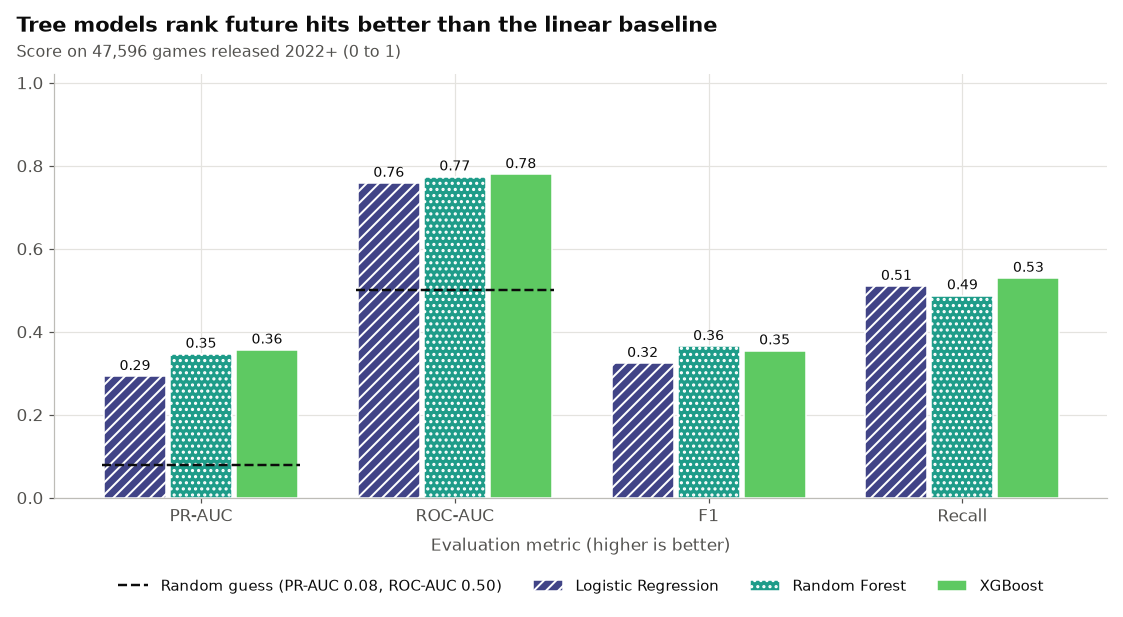

In [9]:
m3 = metrics.drop("Baseline (random)")
cols = ["PR-AUC", "ROC-AUC", "F1", "Recall"]
fig, ax = plt.subplots(figsize=(10, 5.4), layout="constrained")
w = 0.26
x = np.arange(len(cols))
for i, name in enumerate(m3.index):
    vals = m3.loc[name, cols].values
    bars = ax.bar(x + (i - 1) * w, vals, w * 0.94, color=C[name], hatch=HATCH[name],
                  edgecolor="white", linewidth=1, label=name)
    for b, v in zip(bars, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.2f}", ha="center", fontsize=9, color=INK)
for xi, val in [(x[0], y_test.mean()), (x[1], 0.5)]:
    ax.hlines(val, xi - 1.5 * w, xi + 1.5 * w, colors=INK, linestyles="--", linewidth=1.6, zorder=3,
              label=f"Random guess (PR-AUC {y_test.mean():.2f}, ROC-AUC 0.50)" if xi == x[0] else None)
ax.set_xticks(x, cols); ax.set_ylim(0, 1.02)
label_axes(ax, "Tree models rank future hits better than the linear baseline",
           "Evaluation metric (higher is better)", "Score on 47,596 games released 2022+ (0 to 1)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4)
save(fig, "01_model_comparison.png")

### 5.2 Precision–recall and ROC curves

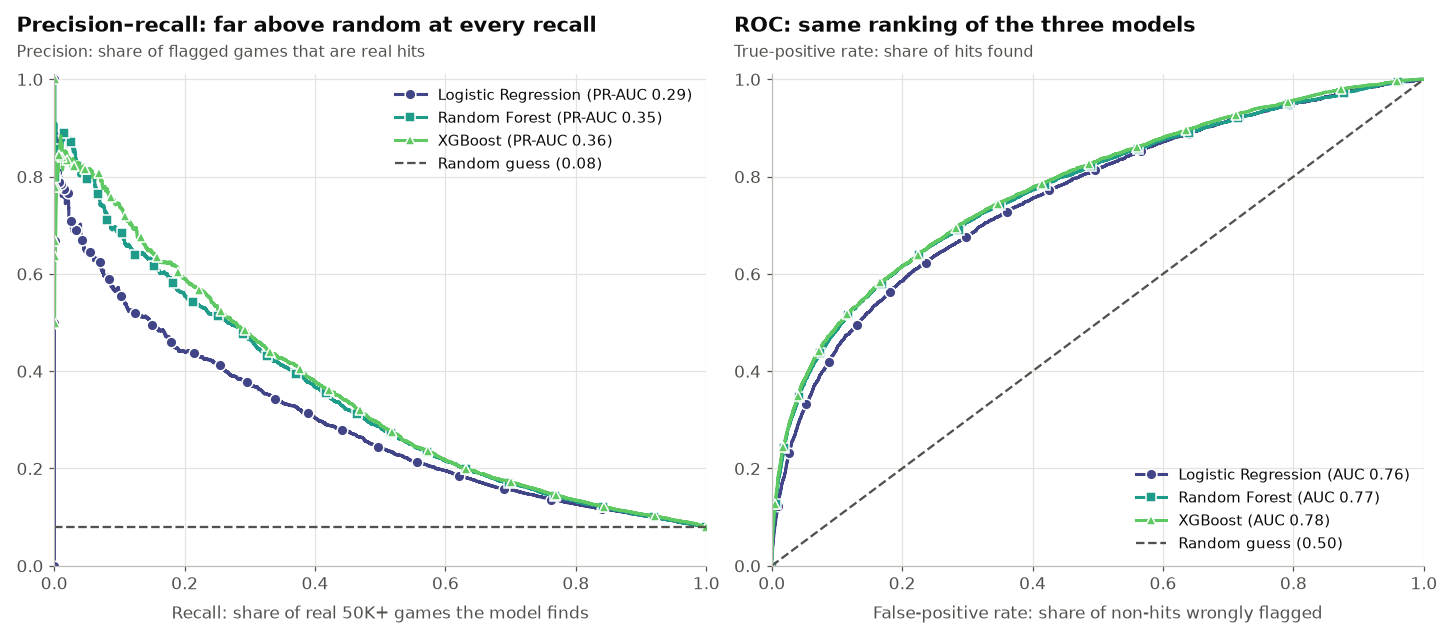

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.6), layout="constrained")
for name, p in test_proba.items():
    pr, rc, _ = precision_recall_curve(y_test, p)
    axes[0].plot(rc, pr, color=C[name], marker=MARK[name], markevery=0.08, ms=7, mec="white", mew=1,
                 label=f"{name} (PR-AUC {average_precision_score(y_test, p):.2f})")
    fpr, tpr, _ = roc_curve(y_test, p)
    axes[1].plot(fpr, tpr, color=C[name], marker=MARK[name], markevery=0.08, ms=7, mec="white", mew=1,
                 label=f"{name} (AUC {roc_auc_score(y_test, p):.2f})")
axes[0].axhline(y_test.mean(), color=INK2, ls="--", lw=1.5, label=f"Random guess ({y_test.mean():.2f})")
axes[1].plot([0, 1], [0, 1], color=INK2, ls="--", lw=1.5, label="Random guess (0.50)")
label_axes(axes[0], "Precision–recall: far above random at every recall",
           "Recall: share of real 50K+ games the model finds", "Precision: share of flagged games that are real hits")
label_axes(axes[1], "ROC: same ranking of the three models",
           "False-positive rate: share of non-hits wrongly flagged", "True-positive rate: share of hits found")
for a in axes:
    a.set_xlim(0, 1); a.set_ylim(0, 1.01)
axes[0].legend(loc="upper right"); axes[1].legend(loc="lower right")
save(fig, "02_pr_roc_curves.png")

**Precision–recall:** the tree models stay well above the random line (8%) across the full range of recall. At low recall, roughly 7 in 10 of the games the model is most confident about really reached 50K+. The gap to logistic regression is largest exactly there, among the top-ranked games, which is where a publisher or investor would look.

### 5.3 Confusion matrix (best model, validation-tuned threshold)

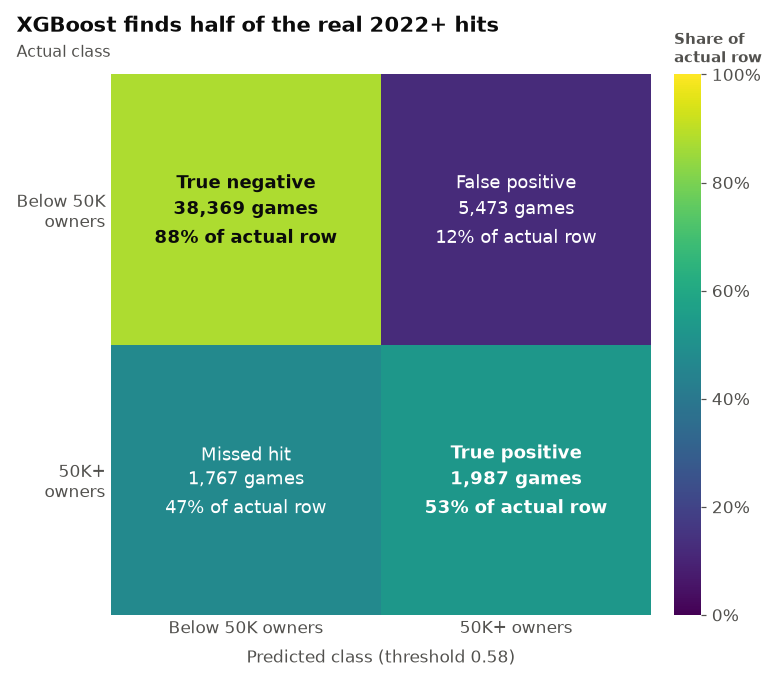

Precision 0.27 vs base rate 0.08 -> a flagged game is 3.4x more likely to be a hit


In [11]:
BEST = metrics.drop("Baseline (random)")["PR-AUC"].idxmax()
p_best = test_proba[BEST]
yhat_best = (p_best >= thresholds[BEST]).astype(int)
cm = confusion_matrix(y_test, yhat_best)
share = cm / cm.sum(axis=1, keepdims=True)
tags = [["True negative", "False positive"], ["Missed hit", "True positive"]]

fig, ax = plt.subplots(figsize=(8, 6), layout="constrained")
im = ax.imshow(share, cmap=HEAT_CMAP, vmin=0, vmax=1)
ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
for i in range(2):
    for j in range(2):
        ax.text(j, i, f"{tags[i][j]}\n{cm[i, j]:,} games\n{share[i, j]:.0%} of actual row", ha="center", va="center",
                fontsize=11.5, linespacing=1.5, color=INK if share[i, j] >= 0.65 else "white",
                fontweight="bold" if i == j else "normal")
ax.set_xticks([0, 1], ["Below 50K owners", "50K+ owners"]); ax.set_yticks([0, 1], ["Below 50K\nowners", "50K+\nowners"])
ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.05, pad=0.03)
cb.ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0)); cb.outline.set_visible(False)
cb.ax.set_title("Share of\nactual row", fontsize=10, color=INK2, loc="left", pad=8)
label_axes(ax, f"{BEST} finds half of the real 2022+ hits", f"Predicted class (threshold {thresholds[BEST]:.2f})",
           "Actual class")
save(fig, "03_confusion_matrix.png")
print(f"Precision {precision_score(y_test, yhat_best):.2f} vs base rate {y_test.mean():.2f} "
      f"-> a flagged game is {precision_score(y_test, yhat_best) / y_test.mean():.1f}x more likely to be a hit")

**What the threshold means in practice.** With the threshold picked on the 2020–21 validation years, XGBoost finds **just over half of all real 2022+ hits (recall 0.53)**. About **27% of the games it flags are real hits, versus 8% for a random pick (3.4x)**. Missing half the hits is expected: many outcomes depend on things not in the store data (marketing, streamers, quality, timing). The model screens games; it does not promise success.

### 5.4 Lift: hit rate by predicted-probability decile

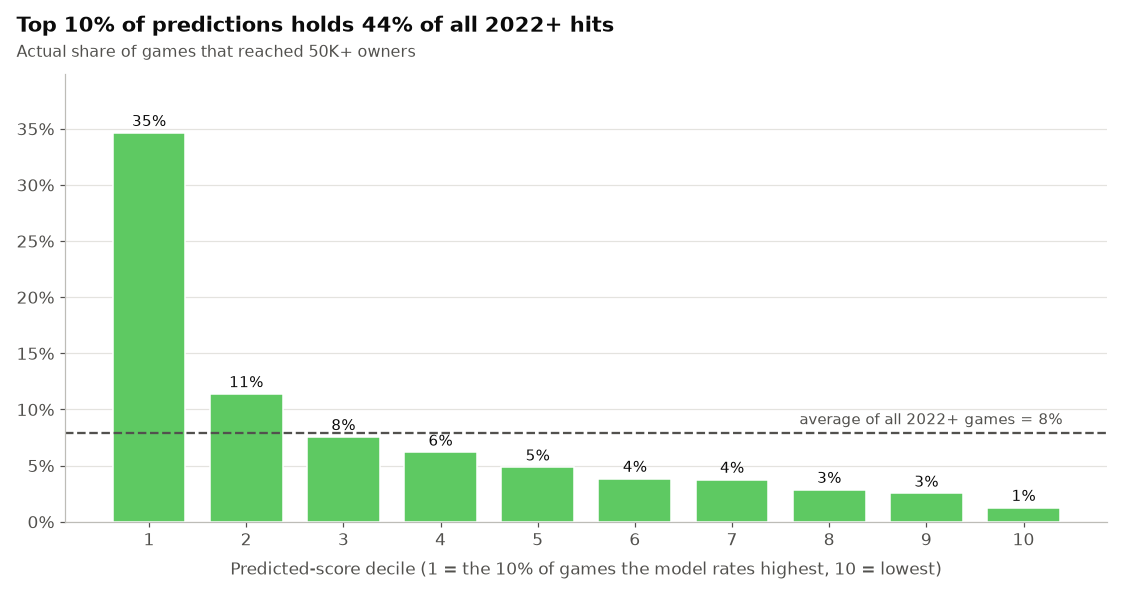

,hit_rate,size,hits,share_of_all_hits
decile,,,,
1,34.6%,4760,1649,43.9%
2,11.4%,4759,542,14.4%
3,7.6%,4760,360,9.6%
4,6.2%,4759,294,7.8%
5,4.9%,4760,231,6.2%
6,3.8%,4759,183,4.9%
7,3.8%,4760,179,4.8%
8,2.9%,4759,136,3.6%
9,2.5%,4760,120,3.2%


In [12]:
dec = pd.qcut(pd.Series(p_best).rank(method="first"), 10, labels=False)
lift = (pd.DataFrame({"decile": 10 - dec, "y": y_test.values})
        .groupby("decile")["y"].agg(["mean", "size", "sum"]).rename(columns={"mean": "hit_rate", "sum": "hits"}))
lift["share_of_all_hits"] = lift["hits"] / lift["hits"].sum()
lift.to_csv(OUT_DIR / "lift_by_decile.csv")

fig, ax = plt.subplots(figsize=(10, 5.2), layout="constrained")
bars = ax.bar(lift.index, lift.hit_rate, 0.75, color=C[BEST], edgecolor="white", linewidth=1)
for b, r in zip(bars, lift.hit_rate):
    ax.text(b.get_x() + b.get_width() / 2, r + 0.006, f"{r:.0%}", ha="center", fontsize=9.5, color=INK)
ax.axhline(y_test.mean(), color=INK2, ls="--", lw=1.5)
ax.text(10.4, y_test.mean() + 0.008, f"average of all 2022+ games = {y_test.mean():.0%}", ha="right", fontsize=9.5,
        color=INK2, bbox=dict(facecolor=SURF, edgecolor="none", pad=1.5))
ax.set_ylim(0, lift.hit_rate.max() * 1.15)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xticks(lift.index, [f"{d}" for d in lift.index]); ax.grid(axis="x", visible=False)
label_axes(ax, f"Top 10% of predictions holds {lift.share_of_all_hits.iloc[0]:.0%} of all 2022+ hits",
           "Predicted-score decile (1 = the 10% of games the model rates highest, 10 = lowest)",
           "Actual share of games that reached 50K+ owners")
save(fig, "04_lift_by_decile.png")
lift.style.format({"hit_rate": "{:.1%}", "share_of_all_hits": "{:.1%}"})

**Business view.** If you rank every new 2022+ release by predicted score, **the top 10% has a 35% hit rate (4.4x the average) and contains 44% of all hits**. The bottom half of the ranking has a 1–4% hit rate. For a publisher deciding which pitches to fund, or for Steam deciding what to feature, this ranking is the most useful output, more useful than a yes/no label.

## 6 · Explainability

### 6.1 Permutation importance (model-agnostic)
How much test PR-AUC drops when one feature is shuffled - measured on the unseen 2022+ games, so it reflects what generalises.

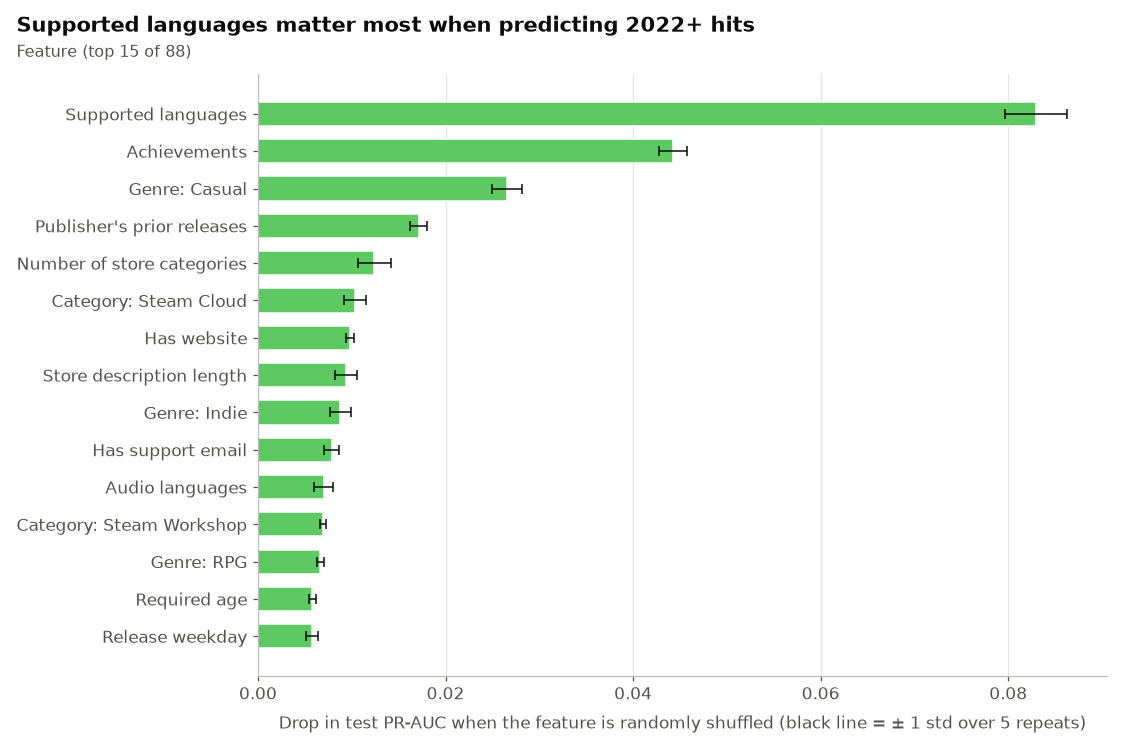

In [13]:
pi = permutation_importance(models[BEST], X_test, y_test, scoring="average_precision",
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
perm = (pd.DataFrame({"feature": FEATURES, "perm_mean": pi.importances_mean, "perm_std": pi.importances_std})
        .sort_values("perm_mean", ascending=False))
top = perm.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6.6), layout="constrained")
ax.barh([pretty(f) for f in top.feature], top.perm_mean, xerr=top.perm_std, color=C[BEST], height=0.65,
        edgecolor="white", linewidth=1, error_kw=dict(ecolor=INK, lw=1, capsize=3))
ax.grid(axis="y", visible=False)
label_axes(ax, f"{pretty(perm.feature.iloc[0])} matter most when predicting 2022+ hits",
           "Drop in test PR-AUC when the feature is randomly shuffled (black line = ± 1 std over 5 repeats)",
           "Feature (top 15 of 88)")
save(fig, "05_permutation_importance.png")

### 6.2 SHAP - direction and size of each feature's effect

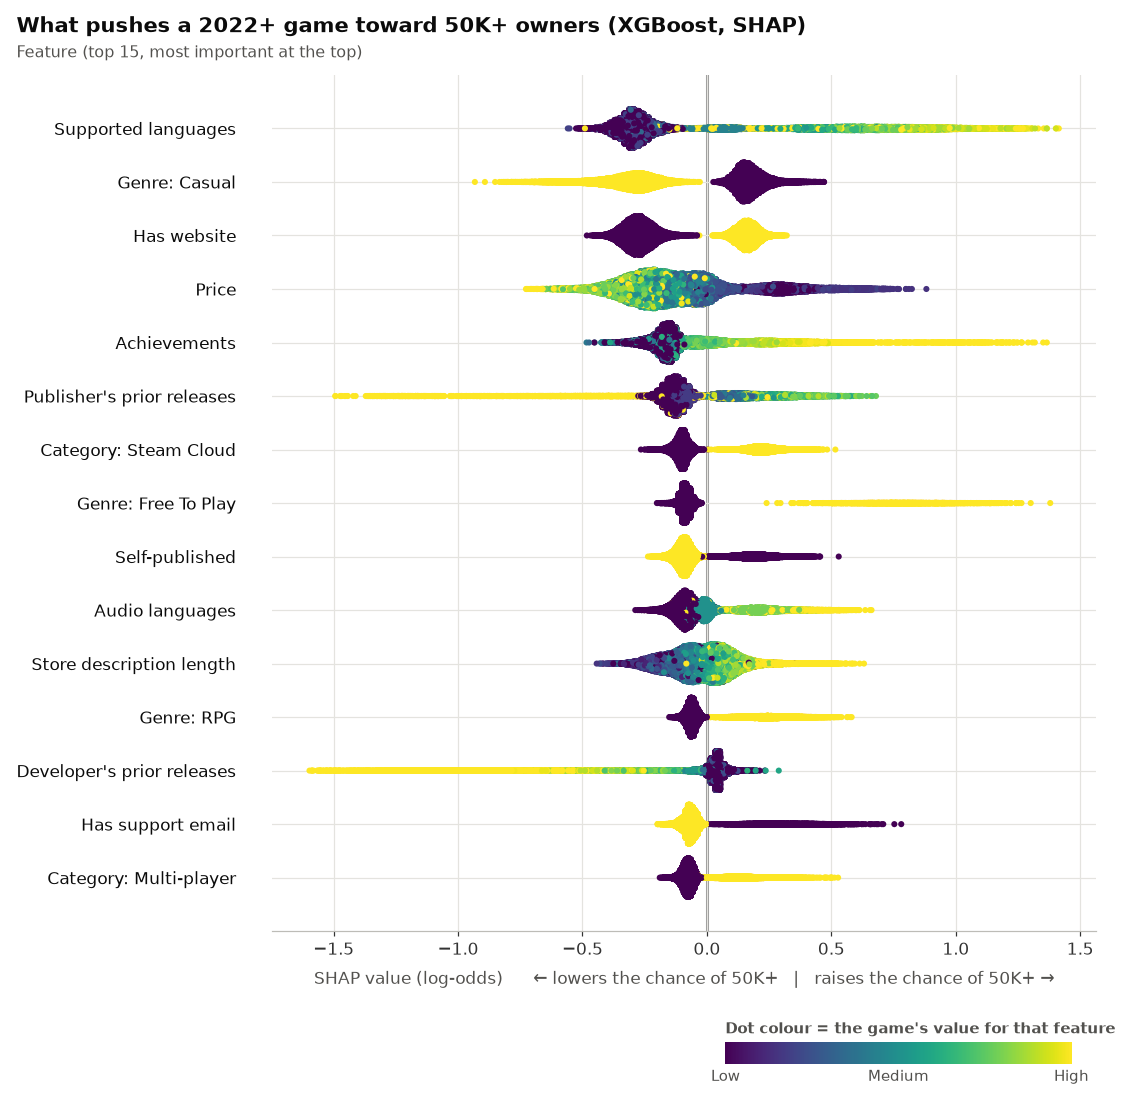

In [14]:
booster = models["XGBoost"].get_booster()
contrib = booster.predict(xgb.DMatrix(X_test, feature_names=FEATURES), pred_contribs=True)
shap_vals, shap_base = contrib[:, :-1], contrib[0, -1]
mean_abs = pd.Series(np.abs(shap_vals).mean(0), index=FEATURES).sort_values(ascending=False)

fig = plt.figure(figsize=(10.5, 8.6))
shap.summary_plot(shap_vals, X_test.rename(columns=pretty), max_display=15, show=False,
                  plot_size=None, cmap=SHAP_CMAP, color_bar=False)
ax = plt.gca()
ax.set_xlabel("SHAP value (log-odds)      ← lowers the chance of 50K+   |   raises the chance of 50K+ →",
              fontsize=11, color=INK2, labelpad=8)
ax.tick_params(axis="y", labelsize=11, colors=INK)
label_axes(ax, "What pushes a 2022+ game toward 50K+ owners (XGBoost, SHAP)", ax.get_xlabel(),
           "Feature (top 15, most important at the top)")
# horizontal colour key under the plot - read left to right, no rotated text
cax = ax.inset_axes([0.55, -0.155, 0.42, 0.025])
cb = fig.colorbar(ScalarMappable(norm=Normalize(0, 1), cmap=plt.get_cmap(SHAP_CMAP)), cax=cax, orientation="horizontal")
cb.set_ticks([0, 0.5, 1], labels=["Low", "Medium", "High"]); cb.outline.set_visible(False)
cax.tick_params(length=0, labelsize=10, colors=INK2)
cax.set_title("Dot colour = the game's value for that feature", fontsize=10, color=INK2, loc="left", pad=6)
save(plt.gcf(), "06_shap_summary.png")

**How to read it:** each dot is one 2022+ game. Dots to the right raise the predicted chance of 50K+, dots to the left lower it. Red means a high value of the feature, blue a low value.

* **Localisation is the strongest lever we can see.** Games with more supported (and voiced) languages are pushed strongly toward success. One-language games are pushed down.
* **Genre: Casual is a clear negative.** It is the most crowded category (21,595 test games, 4.9% hit rate).
* **Signals of investment and polish help:** having a website, Steam Achievements, Steam Cloud, a longer store description, multiplayer support.
* **Price:** cheap and free games get a boost, and anything above about $5 gets a small, flat penalty. The EDA showed $20–40 games with the highest raw hit rate. Once languages, publisher experience and features are held constant, price itself is not what makes those games succeed: bigger studios charge more *and* invest more.
* **Experience has a sweet spot.** A publisher with some earlier releases helps. Developers and publishers with very many releases (asset-flip and shovelware mills) are pushed down hard.
* **Self-published** games and games listing only a **support email** (typical of solo developers) score lower.

### 6.3 SHAP dependence - how the effect changes along the feature

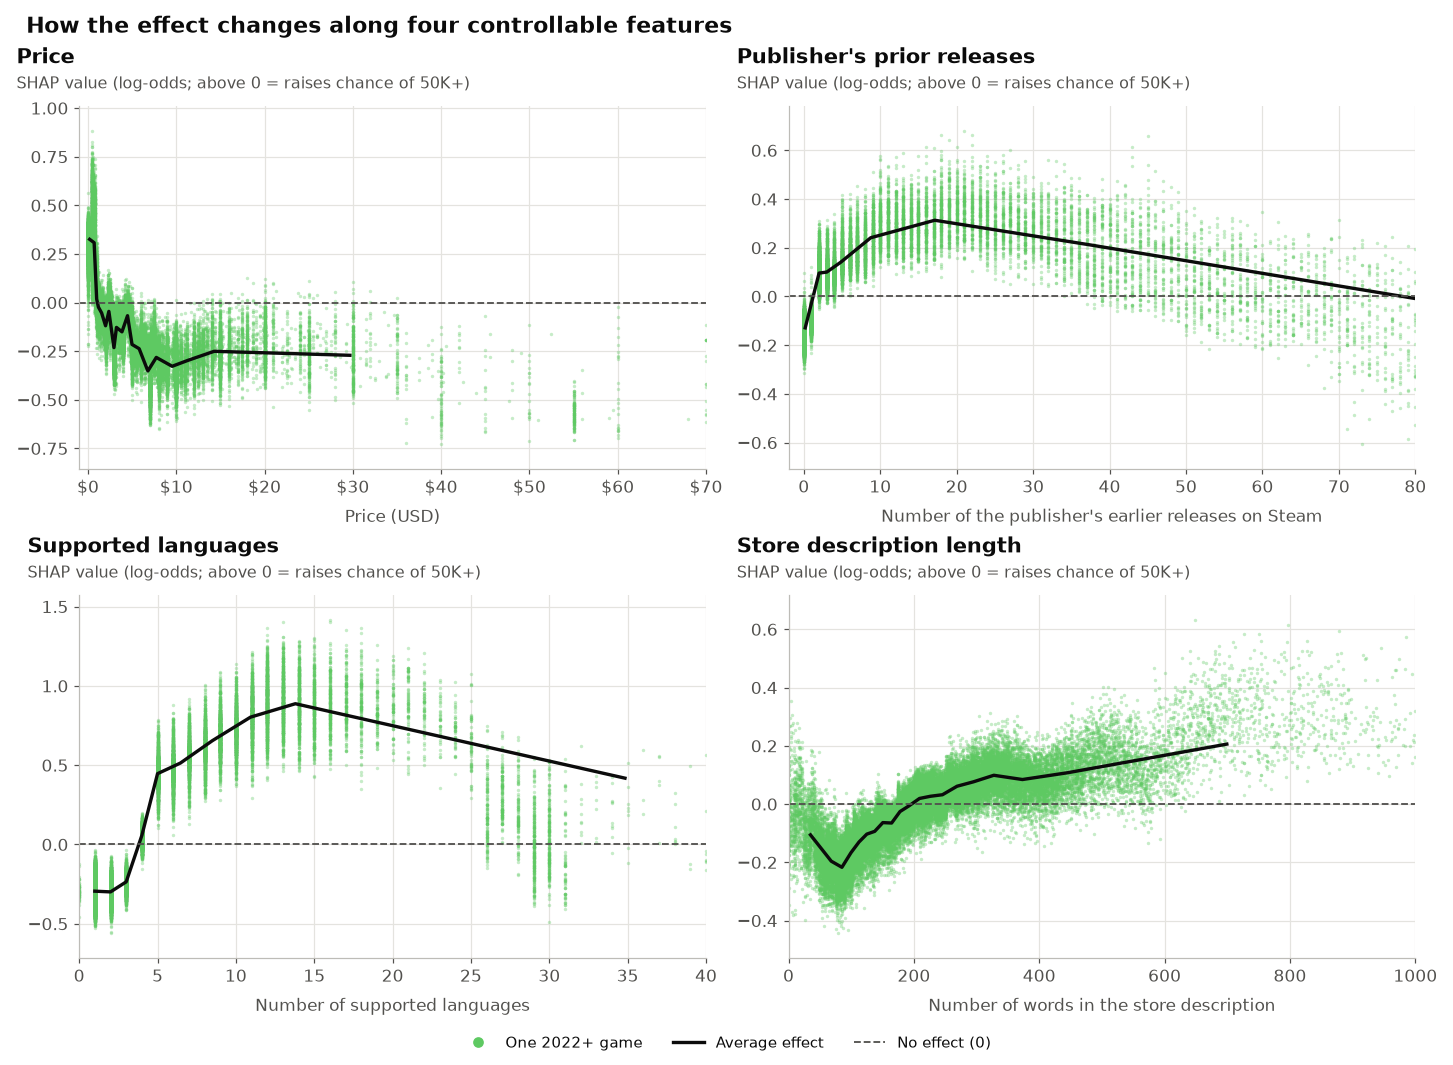

In [15]:
def shap_dep(ax, feat, xlabel, transform=None, fmt=None, xlim=None):
    i = FEATURES.index(feat)
    xv = X_test[feat].values
    xv = transform(xv) if transform else xv
    ax.scatter(xv, shap_vals[:, i], s=5, alpha=0.35, color=C["XGBoost"], linewidths=0, rasterized=True)
    bins = pd.qcut(xv, 20, duplicates="drop") if len(np.unique(xv)) > 20 else xv
    trend = pd.DataFrame({"x": xv, "s": shap_vals[:, i], "b": bins}).groupby("b", observed=True)[["x", "s"]].mean()
    ax.plot(trend.x, trend.s, color=INK, lw=2.2)
    ax.axhline(0, color=INK2, lw=1.2, ls="--")
    if xlim:
        ax.set_xlim(*xlim)
        vis = shap_vals[(xv >= xlim[0]) & (xv <= xlim[1]), i]
        pad = 0.08 * (vis.max() - vis.min())
        ax.set_ylim(vis.min() - pad, vis.max() + pad)
    if fmt: ax.xaxis.set_major_formatter(fmt)
    label_axes(ax, pretty(feat), xlabel, "SHAP value (log-odds; above 0 = raises chance of 50K+)")

fig, axes = plt.subplots(2, 2, figsize=(13, 9.5), layout="constrained")
shap_dep(axes[0, 0], "log_price", "Price (USD)", transform=np.expm1, fmt=mtick.StrMethodFormatter("${x:,.0f}"), xlim=(-1, 70))
shap_dep(axes[0, 1], "log_pub_prior", "Number of the publisher's earlier releases on Steam", transform=np.expm1, xlim=(-2, 80))
shap_dep(axes[1, 0], "log_languages", "Number of supported languages", transform=np.expm1, xlim=(0, 40))
shap_dep(axes[1, 1], "log_about_words", "Number of words in the store description", transform=np.expm1, xlim=(0, 1000))
handles = [Line2D([], [], marker="o", ls="", color=C["XGBoost"], ms=6, label="One 2022+ game"),
           Line2D([], [], color=INK, lw=2.2, label="Average effect"),
           Line2D([], [], color=INK2, lw=1.2, ls="--", label="No effect (0)")]
fig.legend(handles=handles, loc="outside lower center", ncol=3)
fig.suptitle("How the effect changes along four controllable features", x=0.01, ha="left",
             fontweight="bold", fontsize=14.5)
save(fig, "07_shap_dependence.png")

* **Price:** the largest positive effect is at $0–1, it drops below zero around $3–5 and stays roughly flat afterwards. There is no premium "sweet spot" once other factors are controlled.
* **Publisher's earlier releases:** effect rises quickly over the first few earlier releases and peaks at about 15–20 (an established label), then fades. Very prolific publishers get no benefit.
* **Supported languages:** the clearest curve. 1–3 languages hurt, the effect turns positive at about 5 languages, and it peaks around **10–15 languages**. Beyond about 25 it declines again, likely machine-translated catalogue games.
* **Store description:** very short pages (under ~150 words) are penalised; effort put into the store page pays off steadily up to about 400+ words.

### 6.4 Genre: actual vs model-predicted hit rate on the test years

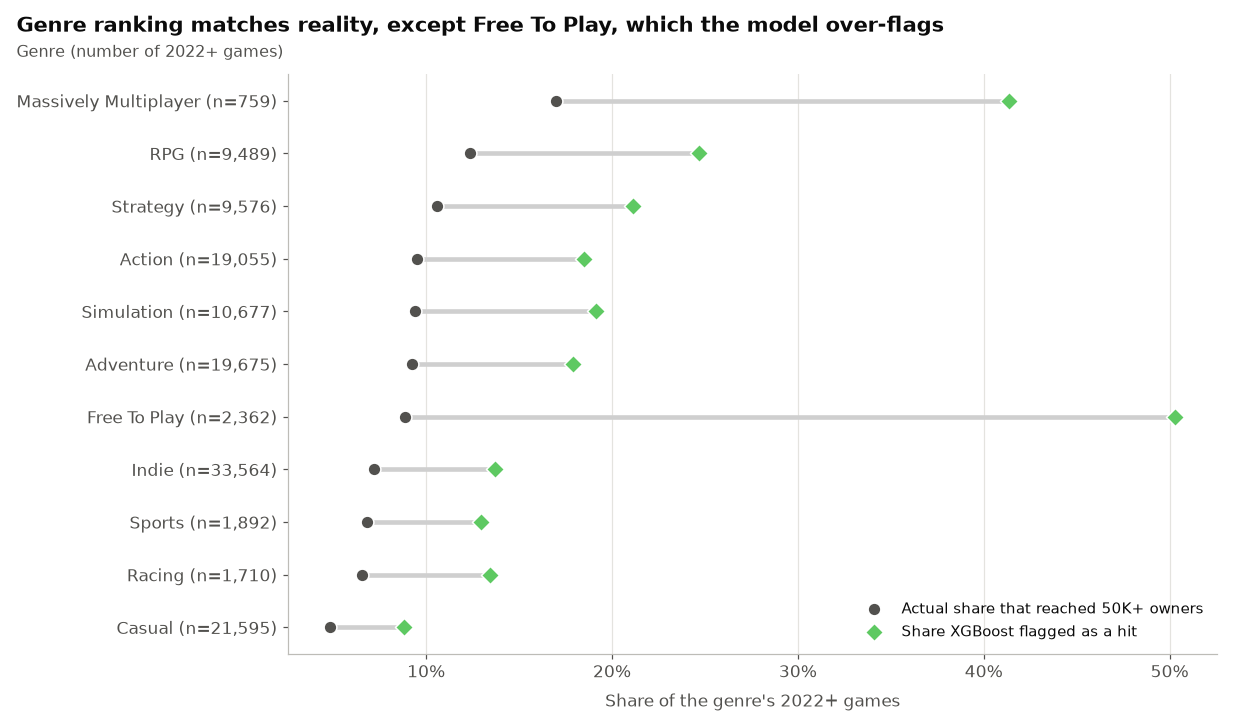

Rank correlation actual vs flagged: 0.79


In [16]:
gcols = [c for c in genre_X.columns if X_test[c].sum() >= 300]
flag = (p_best >= thresholds[BEST])
g = pd.DataFrame([{"genre": c[6:], "games": int(X_test[c].sum()),
                   "actual_rate": y_test[X_test[c] == 1].mean(),
                   "flagged_rate": flag[X_test[c].values == 1].mean(),
                   "precision_in_genre": y_test[(X_test[c] == 1) & flag].mean()} for c in gcols]
                ).sort_values("actual_rate")
g.to_csv(OUT_DIR / "genre_actual_vs_predicted.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 6.4), layout="constrained")
yy = np.arange(len(g))
ax.hlines(yy, g.actual_rate, g.flagged_rate, color="#cfcfcf", lw=3)
ax.scatter(g.actual_rate, yy, s=70, marker="o", color=INK2, edgecolor="white", lw=1, zorder=3,
           label="Actual share that reached 50K+ owners")
ax.scatter(g.flagged_rate, yy, s=70, marker="D", color=C[BEST], edgecolor="white", lw=1, zorder=3,
           label=f"Share {BEST} flagged as a hit")
ax.set_yticks(yy, [f"{n} (n={k:,})" for n, k in zip(g.genre, g.games)])
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.grid(axis="y", visible=False)
label_axes(ax, "Genre ranking matches reality, except Free To Play, which the model over-flags",
           "Share of the genre's 2022+ games", "Genre (number of 2022+ games)")
ax.legend(loc="lower right")
save(fig, "08_genre_actual_vs_predicted.png")
print("Rank correlation actual vs flagged:", round(g[["actual_rate", "flagged_rate"]].corr("spearman").iloc[0, 1], 2))

Across genres, the share of games the model flags follows the real hit rate closely (Spearman correlation about 0.8): Massively Multiplayer, RPG and Strategy rank highest; Casual, Racing and Sports rank lowest, the same order as the EDA genre chart.

**The exception is Free To Play.** The model flags about half of new F2P games but only 9% reached 50K+. In the training years F2P was a strong signal (about 32% of 2019–21 F2P games became hits). Since then F2P releases doubled (1,027 in 2024) and the hit rate collapsed to 6% (2024) and 3% (2025). This is **market saturation that the model cannot learn from the past**, and a useful warning: *free* is no longer a shortcut to an audience on Steam.

## 7 · Export results for the dashboards

* `model_metrics.csv` - test metrics for every model
* `feature_importance.csv` - permutation importance + mean |SHAP| per feature
* `test_predictions.csv` - every 2022+ game: predicted probability, predicted label, actual label, top 3 SHAP drivers
* `xgb_model.json` + `model_features.json` - load in Streamlit/Dash for a *what-if* predictor
* `lift_by_decile.csv`, `genre_actual_vs_predicted.csv`

In [17]:
imp = perm.set_index("feature").join(mean_abs.rename("mean_abs_shap"))
imp.insert(0, "label", [pretty(f) for f in imp.index])
imp.sort_values("mean_abs_shap", ascending=False).to_csv(OUT_DIR / "feature_importance.csv")

order = np.argsort(-np.abs(shap_vals), axis=1)[:, :3]
def driver(r, k):
    j = order[r, k]; v = shap_vals[r, j]
    return f"{pretty(FEATURES[j])} ({'+' if v > 0 else '−'}{abs(v):.2f})"
pred = df.loc[test_m, ["AppID", "Name", "release_date", "publisher", "genres", "Price", "owners_range"]].copy()
pred["actual_50k"] = y_test.values
pred["prob_xgb"] = test_proba["XGBoost"].round(4)
pred["prob_rf"] = test_proba["Random Forest"].round(4)
pred["prob_lr"] = test_proba["Logistic Regression"].round(4)
pred["pred_50k"] = (test_proba["XGBoost"] >= thresholds["XGBoost"]).astype(int)
pred["outcome"] = np.select([(pred.actual_50k == 1) & (pred.pred_50k == 1), (pred.actual_50k == 0) & (pred.pred_50k == 1),
                             (pred.actual_50k == 1) & (pred.pred_50k == 0)], ["True positive", "False positive", "Missed hit"],
                            "True negative")
for k in range(3):
    pred[f"driver_{k + 1}"] = [driver(r, k) for r in range(len(pred))]
pred.to_csv(OUT_DIR / "test_predictions.csv", index=False)

models["XGBoost"].save_model(OUT_DIR / "xgb_model.json")
json.dump({"features": FEATURES, "labels": {f: pretty(f) for f in FEATURES},
           "threshold": thresholds["XGBoost"], "params": XGB_PARAMS, "n_estimators": XGB_TREES,
           "train_years": "<=2021", "test_years": ">=2022",
           "note": "log_* features are np.log1p of the raw value"},
          open(OUT_DIR / "model_features.json", "w"), indent=2)
for f in sorted(OUT_DIR.iterdir()): print(f"{f.name:35s} {f.stat().st_size / 1e6:6.2f} MB")

README.md                             0.00 MB
feature_importance.csv                0.01 MB
genre_actual_vs_predicted.csv         0.00 MB
lift_by_decile.csv                    0.00 MB
model_features.json                   0.01 MB
model_metrics.csv                     0.00 MB
test_predictions.csv                  9.86 MB
xgb_model.json                        4.50 MB


## 8 · Insights for the project question


**Answer to "What makes a Steam game commercially successful?"** Using only information available before launch, the model ranks future games about 4.5x better than chance. It points to the following:

1. **Reach the world.** Localisation is the single most important controllable factor. Moving from 1–3 to about 10 supported languages has the largest positive effect in the model.
2. **Signal investment.** A real website, a detailed store page, achievements, cloud saves and controller and multiplayer support all add up. These features mark a professionally produced game.
3. **Experience matters, volume does not.** Some publishing history helps. Mass-producing dozens of titles hurts.
4. **Pick the genre with care.** Casual and Indie are the most crowded and have the lowest odds. MMO, RPG and Strategy have the highest.
5. **Price is not the lever.** After controlling for everything else, a higher price does not create success. The EDA price pattern mostly reflects *who* sets higher prices.
6. **The market is getting harder.** Hit rates fell from 21% (≤2021) to 8% (2022+), and F2P lost its advantage. Any success model needs regular retraining.

**Decision use:** publishers and investors can use the score to **prioritise** projects or marketing budget, since the top-10% bucket has a 35% hit rate versus 8% overall. Developers can use the SHAP drivers in the dashboards to see which pre-launch choices (languages, store page, features) would most change their odds.

## 9 · Limitations
* **Owners are SteamSpy estimates in ranges**, so 50K+ is a proxy for commercial success, not revenue.
* **Time on sale**: 2024–25 games have had little time to reach 50K, so part of the low test hit rate is "not yet" rather than "never". The model's absolute probabilities are inflated by class weighting - use them to **rank** games, not as literal chances.
* Some "pre-release" fields can be edited after launch (languages, description, achievements); successful games may add localisations later, which can inflate those effects.
* Screenshot and trailer counts from the original plan were not carried into `steam_clean.csv`, so they are not in this model.
* Associations, not causes: e.g. more languages correlate with success partly because larger studios localise more.